In [1]:
import pandas as pd
df=pd.read_csv('auto_mpg.csv')
df

,mpg,cylinders,displacement,horsepower,weight,acceleration,model_year,origin,name
0,18.0,8,307.0,130.0,3504,12.0,70,usa,chevrolet chevelle malibu
1,15.0,8,350.0,165.0,3693,11.5,70,usa,buick skylark 320
2,18.0,8,318.0,150.0,3436,11.0,70,usa,plymouth satellite
3,16.0,8,304.0,150.0,3433,12.0,70,usa,amc rebel sst
4,17.0,8,302.0,140.0,3449,10.5,70,usa,ford torino
...,...,...,...,...,...,...,...,...,...
393,27.0,4,140.0,86.0,2790,15.6,82,usa,ford mustang gl
394,44.0,4,97.0,52.0,2130,24.6,82,europe,vw pickup
395,32.0,4,135.0,84.0,2295,11.6,82,usa,dodge rampage
396,28.0,4,120.0,79.0,2625,18.6,82,usa,ford ranger


In [2]:
df.drop('name',axis=1,inplace=True)
print(df.columns)

Index(['mpg', 'cylinders', 'displacement', 'horsepower', 'weight',
       'acceleration', 'model_year', 'origin'],
      dtype='object')


In [3]:
from sklearn.preprocessing import LabelEncoder
le=LabelEncoder()
df['origin']=le.fit_transform(df['origin'])
df

,mpg,cylinders,displacement,horsepower,weight,acceleration,model_year,origin
0,18.0,8,307.0,130.0,3504,12.0,70,2
1,15.0,8,350.0,165.0,3693,11.5,70,2
2,18.0,8,318.0,150.0,3436,11.0,70,2
3,16.0,8,304.0,150.0,3433,12.0,70,2
4,17.0,8,302.0,140.0,3449,10.5,70,2
...,...,...,...,...,...,...,...,...
393,27.0,4,140.0,86.0,2790,15.6,82,2
394,44.0,4,97.0,52.0,2130,24.6,82,0
395,32.0,4,135.0,84.0,2295,11.6,82,2
396,28.0,4,120.0,79.0,2625,18.6,82,2


In [4]:
print(df['origin'].unique)


<bound method Series.unique of 0      2
1      2
2      2
3      2
4      2
      ..
393    2
394    0
395    2
396    2
397    2
Name: origin, Length: 398, dtype: int64>


In [5]:
df.isnull().sum()

mpg             0
cylinders       0
displacement    0
horsepower      6
weight          0
acceleration    0
model_year      0
origin          0
dtype: int64

In [6]:
df.fillna(method='ffill',inplace=True)
df.isnull().sum()

C:\Users\nikhi\AppData\Local\Temp\ipykernel_9136\627222060.py:1: FutureWarning: DataFrame.fillna with 'method' is deprecated and will raise in a future version. Use obj.ffill() or obj.bfill() instead.
  df.fillna(method='ffill',inplace=True)


mpg             0
cylinders       0
displacement    0
horsepower      0
weight          0
acceleration    0
model_year      0
origin          0
dtype: int64

In [7]:
x=df.iloc[:,1:8]
y=df[['mpg']]

In [8]:
x

,cylinders,displacement,horsepower,weight,acceleration,model_year,origin
0,8,307.0,130.0,3504,12.0,70,2
1,8,350.0,165.0,3693,11.5,70,2
2,8,318.0,150.0,3436,11.0,70,2
3,8,304.0,150.0,3433,12.0,70,2
4,8,302.0,140.0,3449,10.5,70,2
...,...,...,...,...,...,...,...
393,4,140.0,86.0,2790,15.6,82,2
394,4,97.0,52.0,2130,24.6,82,0
395,4,135.0,84.0,2295,11.6,82,2
396,4,120.0,79.0,2625,18.6,82,2


In [9]:
y

,mpg
0,18.0
1,15.0
2,18.0
3,16.0
4,17.0
...,...
393,27.0
394,44.0
395,32.0
396,28.0


In [10]:
from sklearn.model_selection import train_test_split
x_train, x_test, y_train, y_test = train_test_split(x,y, test_size=0.2)
print("Training set size:", x_train.shape[0])
print("Testing dt size:", x_test.shape[0])

Training set size: 318
Testing dt size: 80


In [11]:
x_train

,cylinders,displacement,horsepower,weight,acceleration,model_year,origin
209,4,120.0,88.0,3270,21.9,76,0
108,4,97.0,88.0,2279,19.0,73,1
86,8,304.0,150.0,3672,11.5,73,2
236,4,140.0,89.0,2755,15.8,77,2
172,4,90.0,71.0,2223,16.5,75,0
...,...,...,...,...,...,...,...
251,8,302.0,139.0,3570,12.8,78,2
9,8,390.0,190.0,3850,8.5,70,2
51,4,79.0,70.0,2074,19.5,71,0
258,6,231.0,105.0,3380,15.8,78,2


In [12]:
x_test


,cylinders,displacement,horsepower,weight,acceleration,model_year,origin
306,6,173.0,115.0,2595,11.3,79,2
167,4,97.0,75.0,2171,16.0,75,1
161,6,250.0,105.0,3897,18.5,75,2
379,4,98.0,70.0,2125,17.3,82,2
115,8,350.0,145.0,4082,13.0,73,2
...,...,...,...,...,...,...,...
277,6,163.0,133.0,3410,15.8,78,0
88,8,302.0,137.0,4042,14.5,73,2
45,6,258.0,110.0,2962,13.5,71,2
350,4,105.0,63.0,2215,14.9,81,2


In [13]:
y_train

,mpg
209,19.0
108,20.0
86,14.0
236,25.5
172,25.0
...,...
251,20.2
9,15.0
51,30.0
258,20.6


In [14]:
y_test

,mpg
306,28.8
167,29.0
161,16.0
379,36.0
115,15.0
...,...
277,16.2
88,14.0
45,18.0
350,34.7


In [15]:
from sklearn.linear_model import LinearRegression
lr=LinearRegression()
lr.fit(x_train, y_train)
y_pred=lr.predict(x_test)
print(y_pred)

[[26.82026897]
 [27.91705126]
 [16.34736313]
 [32.86910969]
 [14.08827688]
 [30.25738689]
 [23.84285529]
 [28.86051483]
 [24.76329776]
 [20.83834314]
 [21.38313424]
 [21.32347156]
 [16.30890563]
 [22.70063765]
 [ 9.83127501]
 [29.50166874]
 [30.71992457]
 [28.34956907]
 [28.05941289]
 [25.40423738]
 [21.71558179]
 [23.19031175]
 [23.42363618]
 [23.76169503]
 [24.60758919]
 [24.16172387]
 [21.03564636]
 [30.05152367]
 [25.19813339]
 [ 8.3352434 ]
 [19.14713452]
 [33.59823063]
 [20.80910544]
 [20.13932159]
 [ 8.98668443]
 [16.8206232 ]
 [17.81982648]
 [31.99056455]
 [22.73263285]
 [29.78836538]
 [24.33398278]
 [28.0472808 ]
 [11.25674361]
 [23.66986239]
 [25.65823827]
 [18.80418612]
 [23.7529706 ]
 [23.87572008]
 [11.89561817]
 [10.94402626]
 [35.49793588]
 [20.39301886]
 [31.33019577]
 [34.27142033]
 [10.82243595]
 [12.22685243]
 [26.06117954]
 [20.50928491]
 [24.01801869]
 [25.66503834]
 [12.20169126]
 [20.41416704]
 [24.58220502]
 [23.94748072]
 [16.93251575]
 [21.28030726]
 [28.93662

In [16]:
from sklearn.metrics import mean_squared_error, mean_absolute_error,r2_score
mse=mean_squared_error(y_test,y_pred)
mae=mean_absolute_error(y_test, y_pred)
r2=r2_score(y_test, y_pred)
print("Mean squared error:",mse)
print("Mean absolute error:",mae)
print("R_squared score:",r2)

Mean squared error: 9.23384847689542
Mean absolute error: 2.3335228469153124
R_squared score: 0.806792174394519


In [17]:
import numpy as np
rmse=np.sqrt(mse)
print(rmse)

3.038724810984933


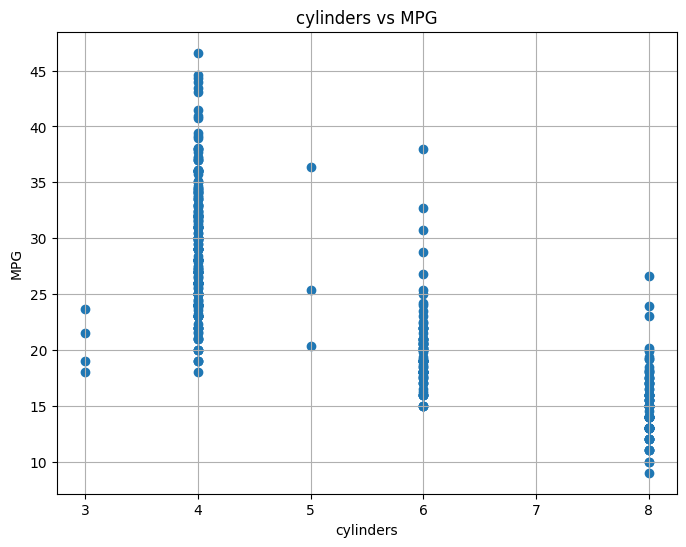

In [19]:
import matplotlib.pyplot as plt
plt.figure(figsize=(8,6))
plt.scatter(x['cylinders'],y)
plt.title("cylinders vs MPG")
plt.xlabel('cylinders')
plt.ylabel('MPG')
plt.grid(True)
plt.show()